In [1]:
!pip install ucimlrepo streamlit -q

import os, re, time, subprocess, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, precision_recall_curve, average_precision_score)

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

In [2]:
data = fetch_ucirepo(id=603)
X = data.data.features.copy()
y = data.data.targets['Y'].copy()

df = pd.concat([X, y], axis=1)
# Normalise the spelling of the passenger column (some versions use 'passanger')
df = df.rename(columns={'passanger': 'passenger'})

print("Shape:", df.shape)
df.head()

Shape: (12684, 26)


,destination,passenger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12684 non-null  object
 1   passenger             12684 non-null  object
 2   weather               12684 non-null  object
 3   temperature           12684 non-null  int64 
 4   time                  12684 non-null  object
 5   coupon                12684 non-null  object
 6   expiration            12684 non-null  object
 7   gender                12684 non-null  object
 8   age                   12684 non-null  object
 9   maritalStatus         12684 non-null  object
 10  has_children          12684 non-null  int64 
 11  education             12684 non-null  object
 12  occupation            12684 non-null  object
 13  income                12684 non-null  object
 14  car                   108 non-null    object
 15  Bar                   12577 non-null

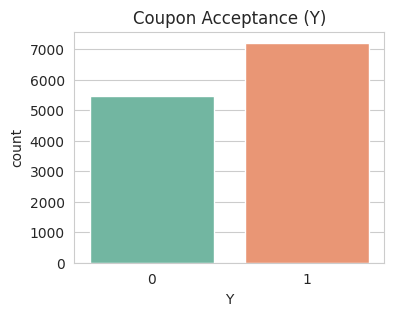

In [3]:
print(df.info())
print("\nTarget distribution:")
print(df['Y'].value_counts())
print((df['Y'].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(4, 3))
sns.countplot(x='Y', data=df, palette='Set2')
plt.title("Coupon Acceptance (Y)")
plt.show()

In [4]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(pd.DataFrame({'Missing': missing, 'Percent': (missing / len(df) * 100).round(2)}))

                      Missing  Percent
car                     12576    99.15
CoffeeHouse               217     1.71
Restaurant20To50          189     1.49
CarryAway                 151     1.19
RestaurantLessThan20      130     1.02
Bar                       107     0.84


In [5]:
# 'car' is almost entirely missing, so drop it
df_clean = df.drop(columns=['car'], errors='ignore').copy()

print("Duplicates:", df_clean.duplicated().sum())

# Mode imputation for remaining missing values
for col in df_clean.columns:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Remaining missing values:", df_clean.isnull().sum().sum())

X = df_clean.drop(columns='Y')
y = df_clean['Y']

numeric_cols = ['temperature']
cat_cols = [c for c in X.columns if c not in numeric_cols]
print("Categorical:", len(cat_cols), "| Numeric:", numeric_cols)

Duplicates: 74
Remaining missing values: 0
Categorical: 23 | Numeric: ['temperature']


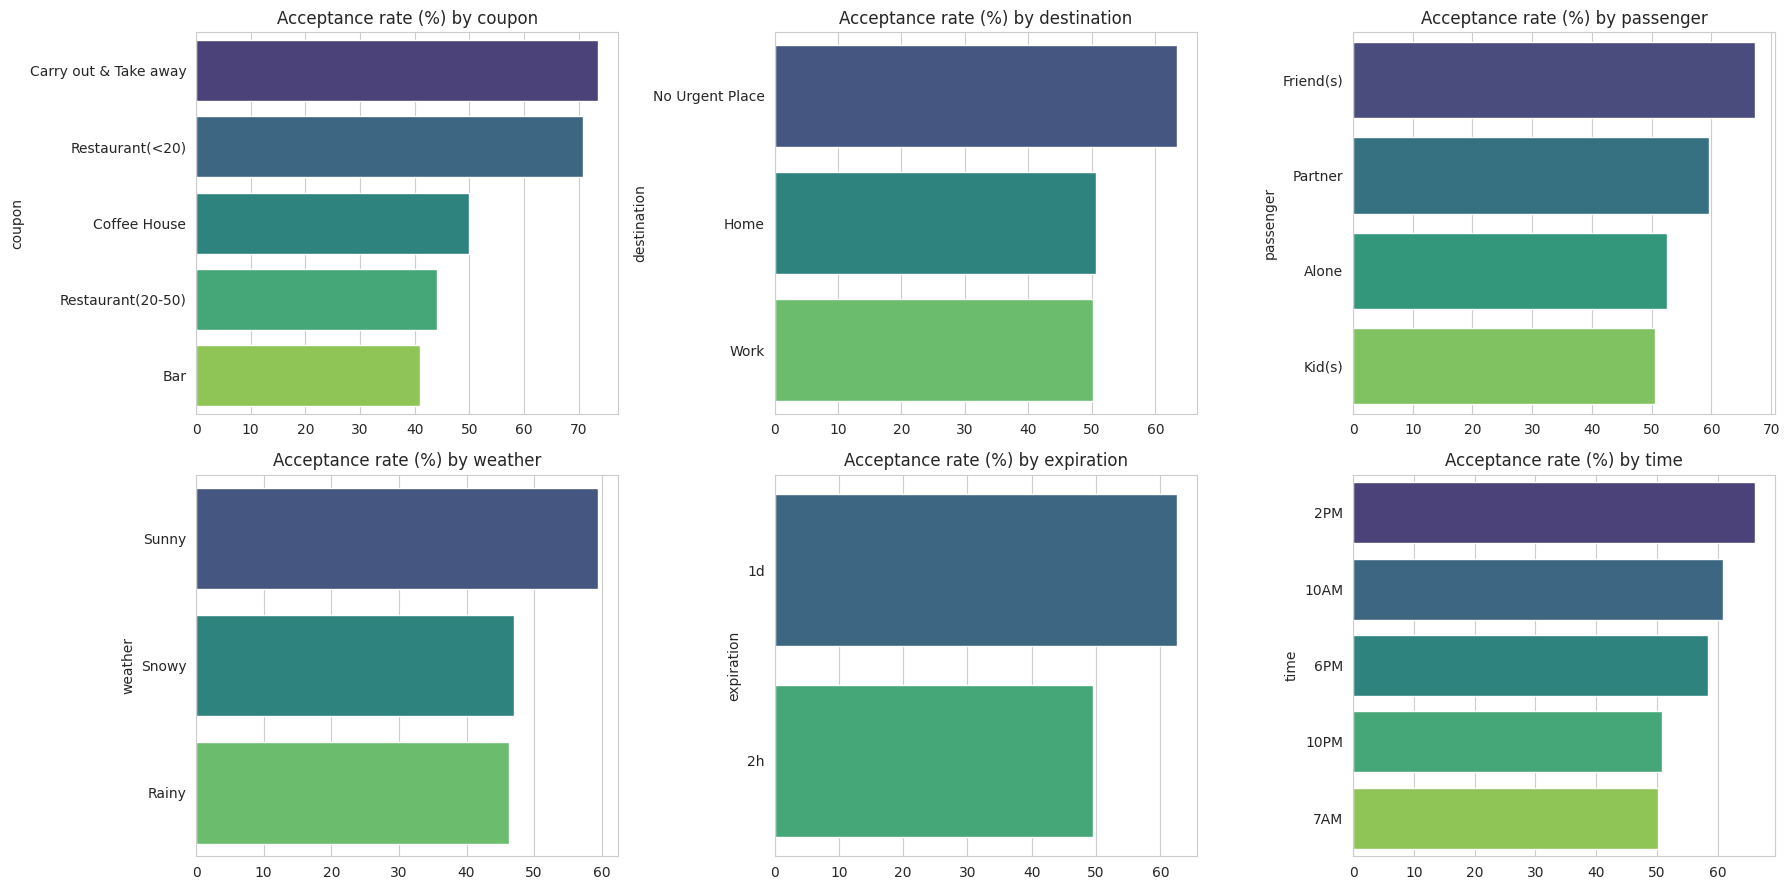

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), ['coupon', 'destination', 'passenger', 'weather', 'expiration', 'time']):
    rate = df_clean.groupby(col)['Y'].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.values, y=rate.index, ax=ax, palette='viridis')
    ax.set_title(f"Acceptance rate (%) by {col}")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# KNN: one-hot for categoricals + MinMax scaling for numeric
knn_pre = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('num', MinMaxScaler(), numeric_cols)
])

# Naive Bayes: ordinal-encode every feature (treated as categorical)
enc = OrdinalEncoder()
nb_cols = cat_cols + numeric_cols
X_enc = pd.DataFrame(enc.fit_transform(X[nb_cols]), columns=nb_cols, index=X.index).astype(int)
Xe_train, Xe_test = X_enc.loc[X_train.index], X_enc.loc[X_test.index]
min_cats = X_enc.max().values + 1

In [8]:
nb = CategoricalNB(alpha=1.0, min_categories=min_cats)
nb.fit(Xe_train, y_train)
y_pred_nb = nb.predict(Xe_test)
y_prob_nb = nb.predict_proba(Xe_test)[:, 1]

print("=== NAIVE BAYES ===")
print("Accuracy :", round(accuracy_score(y_test, y_pred_nb), 4))
print(classification_report(y_test, y_pred_nb, target_names=['Rejected (0)', 'Accepted (1)']))

=== NAIVE BAYES ===
Accuracy : 0.6539
              precision    recall  f1-score   support

Rejected (0)       0.61      0.54      0.57      1095
Accepted (1)       0.68      0.74      0.71      1442

    accuracy                           0.65      2537
   macro avg       0.65      0.64      0.64      2537
weighted avg       0.65      0.65      0.65      2537



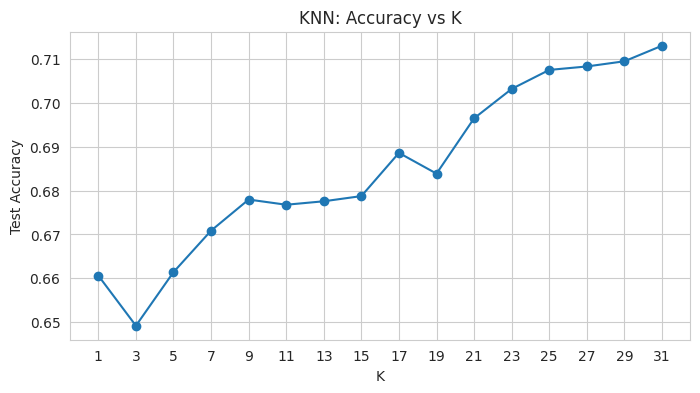

Best K: 31 | Accuracy: 0.713


In [9]:
Xk_train = knn_pre.fit_transform(X_train)
Xk_test = knn_pre.transform(X_test)

k_values = list(range(1, 32, 2))
test_acc = []
for k in k_values:
    m = KNeighborsClassifier(n_neighbors=k, metric='euclidean', n_jobs=-1)
    m.fit(Xk_train, y_train)
    test_acc.append(m.score(Xk_test, y_test))

plt.figure(figsize=(8, 4))
plt.plot(k_values, test_acc, marker='o')
plt.xlabel("K"); plt.ylabel("Test Accuracy"); plt.title("KNN: Accuracy vs K")
plt.xticks(k_values); plt.show()

best_k = k_values[int(np.argmax(test_acc))]
print("Best K:", best_k, "| Accuracy:", round(max(test_acc), 4))

In [10]:
knn = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean', n_jobs=-1)
knn.fit(Xk_train, y_train)
y_pred_knn = knn.predict(Xk_test)
y_prob_knn = knn.predict_proba(Xk_test)[:, 1]

print(f"=== KNN (K={best_k}) ===")
print("Accuracy :", round(accuracy_score(y_test, y_pred_knn), 4))
print(classification_report(y_test, y_pred_knn, target_names=['Rejected (0)', 'Accepted (1)']))

=== KNN (K=31) ===
Accuracy : 0.713
              precision    recall  f1-score   support

Rejected (0)       0.73      0.54      0.62      1095
Accepted (1)       0.71      0.85      0.77      1442

    accuracy                           0.71      2537
   macro avg       0.72      0.69      0.69      2537
weighted avg       0.72      0.71      0.70      2537



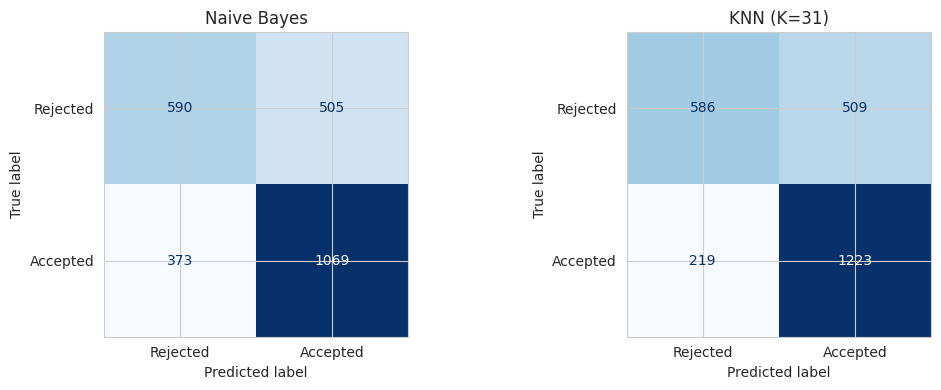

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, name in zip(axes, [y_pred_nb, y_pred_knn], ['Naive Bayes', f'KNN (K={best_k})']):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=['Rejected', 'Accepted']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

,Accuracy,Precision,Recall,F-measure,ROC-AUC
Naive Bayes,0.6539,0.6792,0.7413,0.7089,0.7013
KNN (K=31),0.7130,0.7061,0.8481,0.7706,0.7656


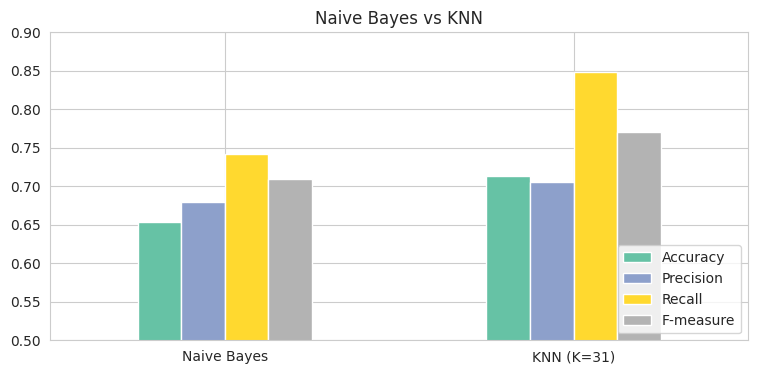

Better algorithm (by F-measure): KNN (K=31)


In [12]:
def metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F-measure': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_prob)
    }

results = pd.DataFrame({
    'Naive Bayes': metrics(y_test, y_pred_nb, y_prob_nb),
    f'KNN (K={best_k})': metrics(y_test, y_pred_knn, y_prob_knn)
}).T.round(4)

display(results)
results.drop(columns='ROC-AUC').plot(kind='bar', figsize=(9, 4), rot=0, colormap='Set2')
plt.title("Naive Bayes vs KNN"); plt.ylim(0.5, 0.9); plt.legend(loc='lower right'); plt.show()

print("Better algorithm (by F-measure):", results['F-measure'].idxmax())

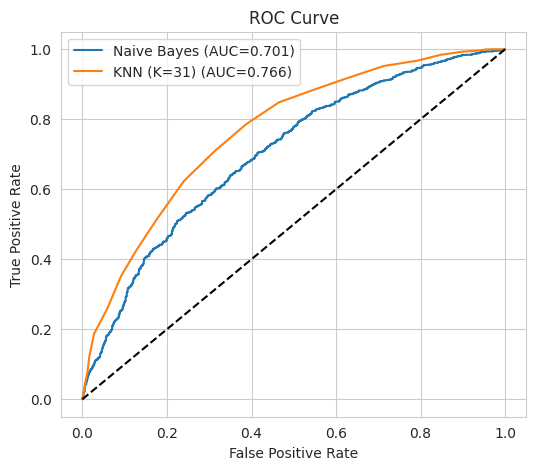

In [13]:
plt.figure(figsize=(6, 5))
for prob, name in [(y_prob_nb, 'Naive Bayes'), (y_prob_knn, f'KNN (K={best_k})')]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, prob):.3f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend(); plt.show()

In [14]:
skf10 = StratifiedKFold(10, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1']

nb_cv = CategoricalNB(alpha=1.0, min_categories=min_cats)
knn_pipe = Pipeline([('pre', knn_pre),
                     ('clf', KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1))])

cv_rows = {}
for name, model, Xin in [('Naive Bayes', nb_cv, X_enc),
                         (f'KNN (K={best_k})', knn_pipe, X)]:
    cv = cross_validate(model, Xin, y, cv=skf10, scoring=scoring)
    cv_rows[name] = {m: cv[f'test_{m}'].mean() for m in scoring}

cv_df = pd.DataFrame(cv_rows).T.round(4)
cv_df.columns = ['Accuracy', 'Precision', 'Recall', 'F-measure']
display(cv_df)

,Accuracy,Precision,Recall,F-measure
Naive Bayes,0.6637,0.6905,0.7406,0.7146
KNN (K=31),0.7129,0.7103,0.8359,0.7680


In [15]:
label = {0: 'Rejected', 1: 'Accepted'}

# ---- Part A: test-set predictions ----
pred_df = X_test.copy()
pred_df['Actual'] = y_test.values
pred_df['NaiveBayes_Pred'] = y_pred_nb
pred_df['NaiveBayes_Prob_Accept'] = y_prob_nb.round(3)
pred_df['KNN_Pred'] = y_pred_knn
pred_df['KNN_Prob_Accept'] = y_prob_knn.round(3)

display(pred_df[['coupon', 'destination', 'passenger', 'weather', 'time', 'age',
                 'Actual', 'NaiveBayes_Pred', 'NaiveBayes_Prob_Accept',
                 'KNN_Pred', 'KNN_Prob_Accept']].head(10))
print("\nBoth models agree on",
      round((pred_df['NaiveBayes_Pred'] == pred_df['KNN_Pred']).mean() * 100, 1), "% of test cases")

# ---- Part B: predict a NEW scenario ----
def predict_coupon(**overrides):
    sample = X.mode().iloc[[0]].copy()
    for col, val in overrides.items():
        sample[col] = val
    sample = sample[X.columns]

    s_nb = pd.DataFrame(enc.transform(sample[nb_cols]), columns=nb_cols).astype(int)
    nb_pred, nb_prob = nb.predict(s_nb)[0], nb.predict_proba(s_nb)[0][1]

    s_knn = knn_pre.transform(sample)
    knn_pred, knn_prob = knn.predict(s_knn)[0], knn.predict_proba(s_knn)[0][1]

    return pd.Series({
        'Naive Bayes': f"{label[nb_pred]} (P(accept)={nb_prob:.2f})",
        f'KNN (K={best_k})': f"{label[knn_pred]} (P(accept)={knn_prob:.2f})"
    })

scenarios = {
    "Coffee House, friends, sunny, 2PM, 80F": dict(coupon='Coffee House', passenger='Friend(s)',
                                                  weather='Sunny', time='2PM', temperature=80),
    "Bar, alone, rainy, 10PM, 55F":           dict(coupon='Bar', passenger='Alone',
                                                  weather='Rainy', time='10PM', temperature=55),
    "Cheap restaurant, partner, 6PM, 2h":     dict(coupon='Restaurant(<20)', passenger='Partner',
                                                  time='6PM', expiration='2h'),
    "Carry out, going home, 1d expiry":       dict(coupon='Carry out & Take away', destination='Home',
                                                  expiration='1d'),
}
display(pd.DataFrame({n: predict_coupon(**p) for n, p in scenarios.items()}).T)

,coupon,destination,passenger,weather,time,age,Actual,NaiveBayes_Pred,NaiveBayes_Prob_Accept,KNN_Pred,KNN_Prob_Accept
11547,Restaurant(20-50),No Urgent Place,Kid(s),Sunny,10PM,31,0,0,0.457,0,0.387
6584,Coffee House,No Urgent Place,Alone,Sunny,6PM,36,0,0,0.324,0,0.387
780,Coffee House,Home,Alone,Sunny,6PM,26,1,1,0.683,1,0.742
8135,Coffee House,No Urgent Place,Alone,Sunny,10AM,31,0,1,0.753,0,0.484
1303,Restaurant(<20),No Urgent Place,Alone,Sunny,2PM,21,1,1,0.908,1,0.710
673,Restaurant(20-50),Work,Alone,Sunny,7AM,31,1,1,0.524,1,0.548
543,Restaurant(<20),Work,Alone,Sunny,7AM,50plus,1,1,0.651,1,0.742
12677,Restaurant(<20),Home,Partner,Sunny,6PM,26,1,1,0.501,0,0.323
3434,Coffee House,No Urgent Place,Friend(s),Sunny,6PM,26,1,1,0.884,1,0.742
11700,Restaurant(20-50),Home,Kid(s),Sunny,10PM,50plus,0,0,0.204,0,0.387



Both models agree on 74.5 % of test cases


,Naive Bayes,KNN (K=31)
"Coffee House, friends, sunny, 2PM, 80F",Accepted (P(accept)=0.80),Accepted (P(accept)=0.55)
"Bar, alone, rainy, 10PM, 55F",Rejected (P(accept)=0.27),Rejected (P(accept)=0.32)
"Cheap restaurant, partner, 6PM, 2h",Accepted (P(accept)=0.74),Accepted (P(accept)=0.68)
"Carry out, going home, 1d expiry",Accepted (P(accept)=0.73),Accepted (P(accept)=0.52)


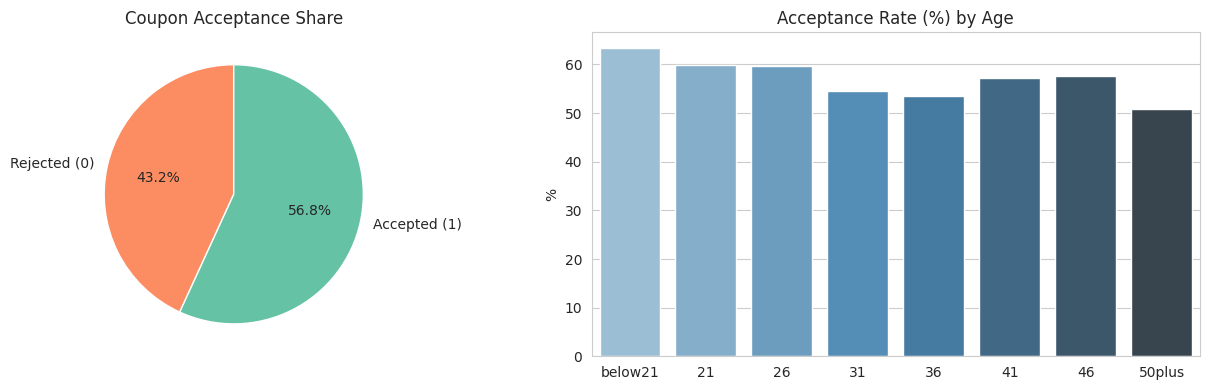

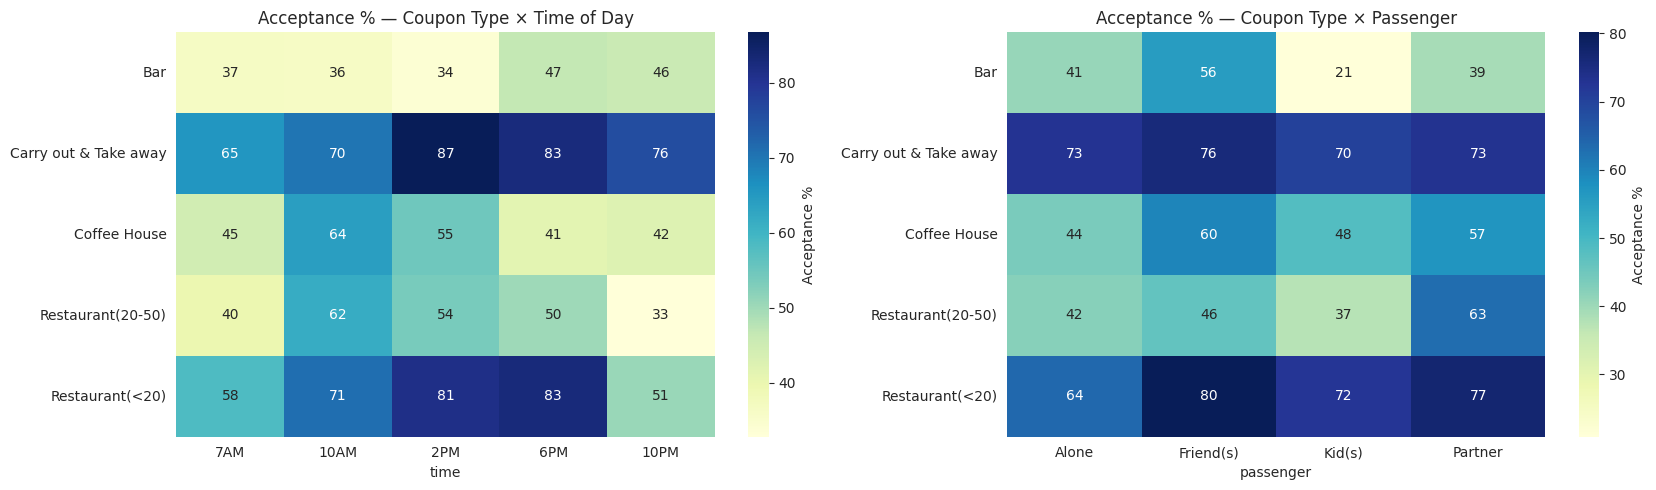

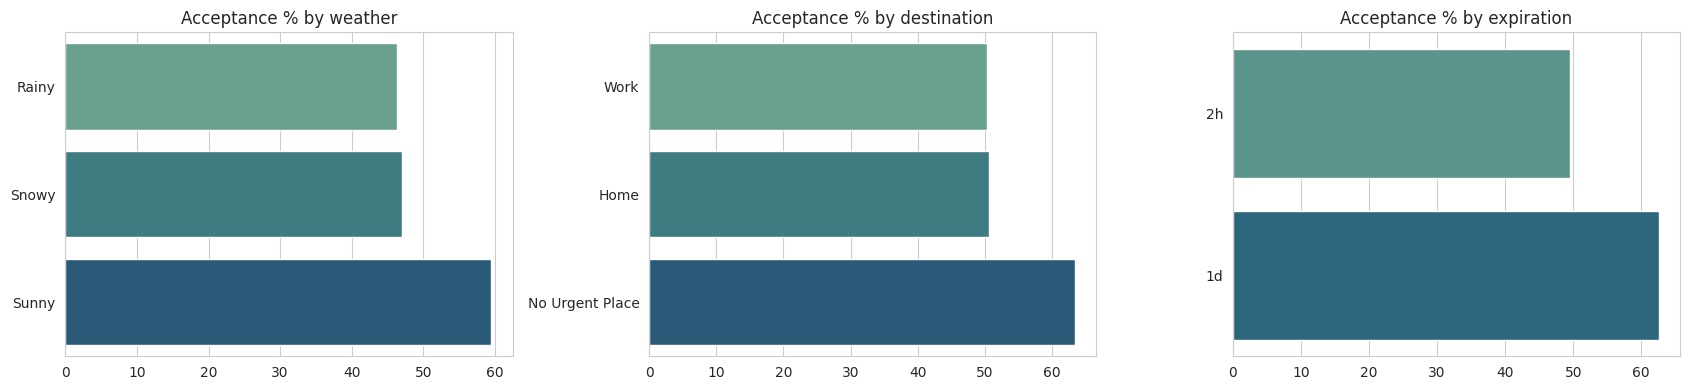

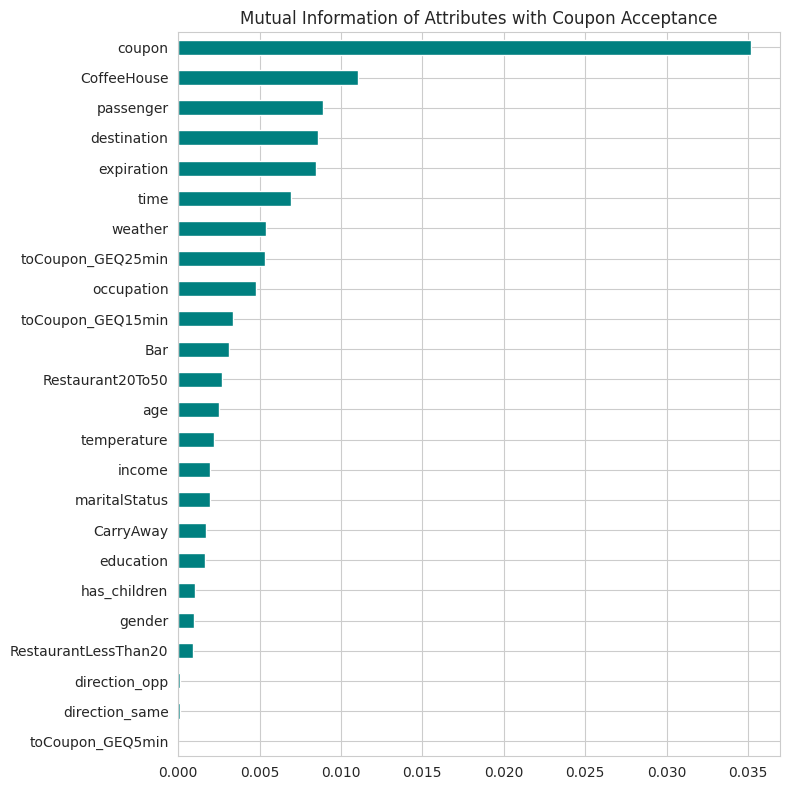

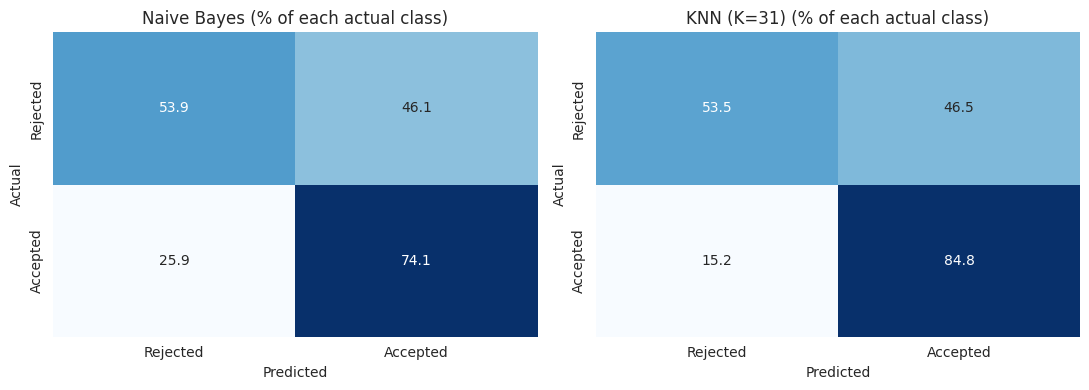

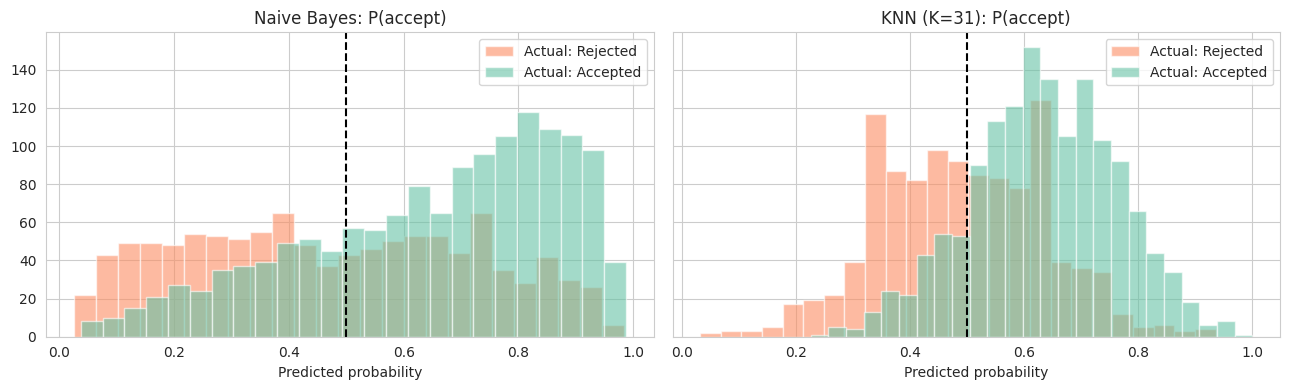

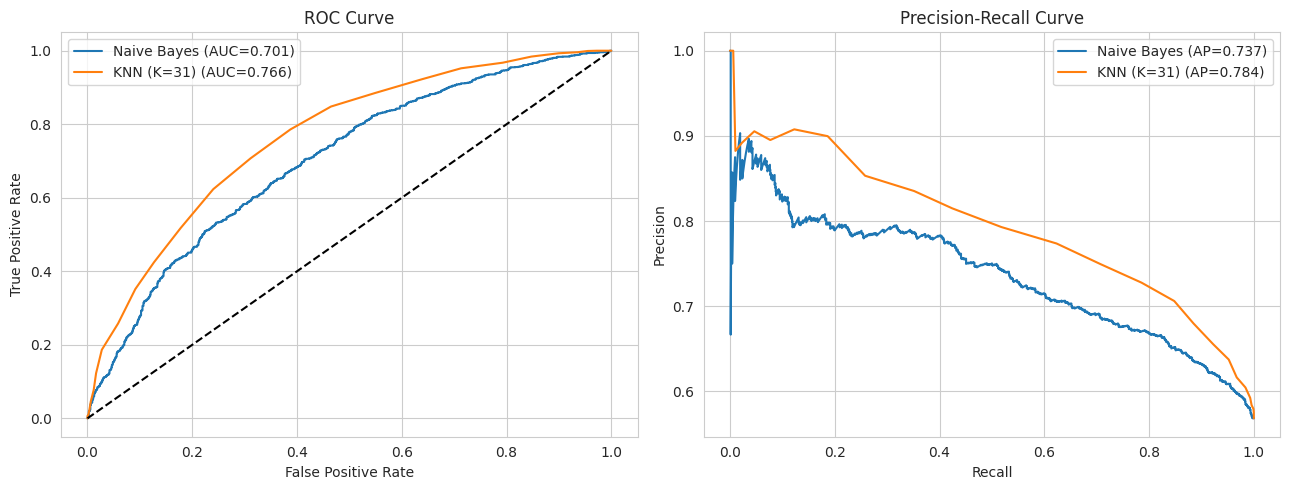

In [16]:
time_order = ['7AM', '10AM', '2PM', '6PM', '10PM']
age_order = ['below21', '21', '26', '31', '36', '41', '46', '50plus']

# 1. Target share + acceptance by age
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df_clean['Y'].value_counts().sort_index().plot.pie(
    ax=ax[0], autopct='%1.1f%%', labels=['Rejected (0)', 'Accepted (1)'],
    colors=['#fc8d62', '#66c2a5'], startangle=90)
ax[0].set_ylabel(''); ax[0].set_title('Coupon Acceptance Share')
age_rate = df_clean.groupby('age')['Y'].mean().reindex(age_order) * 100
sns.barplot(x=age_rate.index, y=age_rate.values, ax=ax[1], palette='Blues_d')
ax[1].set_title('Acceptance Rate (%) by Age'); ax[1].set_xlabel(''); ax[1].set_ylabel('%')
plt.tight_layout(); plt.show()

# 2. Heatmaps
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
for a, col, title in [(ax[0], 'time', 'Coupon Type × Time of Day'),
                      (ax[1], 'passenger', 'Coupon Type × Passenger')]:
    pv = df_clean.pivot_table(values='Y', index='coupon', columns=col, aggfunc='mean') * 100
    if col == 'time':
        pv = pv[[t for t in time_order if t in pv.columns]]
    sns.heatmap(pv, annot=True, fmt='.0f', cmap='YlGnBu', ax=a, cbar_kws={'label': 'Acceptance %'})
    a.set_title(f'Acceptance % — {title}'); a.set_ylabel('')
plt.tight_layout(); plt.show()

# 3. Weather, destination, expiration
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, col in zip(ax, ['weather', 'destination', 'expiration']):
    r = df_clean.groupby(col)['Y'].mean().sort_values() * 100
    sns.barplot(x=r.values, y=r.index, ax=a, palette='crest')
    a.set_title(f'Acceptance % by {col}'); a.set_ylabel('')
plt.tight_layout(); plt.show()

# 4. Feature importance
mi_series = pd.Series(mutual_info_classif(X_enc, y, discrete_features=True, random_state=42),
                      index=X_enc.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 8))
mi_series.sort_values().plot.barh(color='teal')
plt.title('Mutual Information of Attributes with Coupon Acceptance')
plt.tight_layout(); plt.show()

# 5. Normalized confusion matrices
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, pred, name in zip(ax, [y_pred_nb, y_pred_knn], ['Naive Bayes', f'KNN (K={best_k})']):
    cm = confusion_matrix(y_test, pred, normalize='true') * 100
    sns.heatmap(cm, annot=True, fmt='.1f', cmap='Blues', ax=a, cbar=False,
                xticklabels=['Rejected', 'Accepted'], yticklabels=['Rejected', 'Accepted'])
    a.set_title(f'{name} (% of each actual class)'); a.set_xlabel('Predicted'); a.set_ylabel('Actual')
plt.tight_layout(); plt.show()

# 6. Probability distributions
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, prob, name in zip(ax, [y_prob_nb, y_prob_knn], ['Naive Bayes', f'KNN (K={best_k})']):
    a.hist(prob[y_test.values == 0], bins=25, alpha=0.6, label='Actual: Rejected', color='#fc8d62')
    a.hist(prob[y_test.values == 1], bins=25, alpha=0.6, label='Actual: Accepted', color='#66c2a5')
    a.axvline(0.5, color='k', ls='--'); a.set_title(f'{name}: P(accept)')
    a.set_xlabel('Predicted probability'); a.legend()
plt.tight_layout(); plt.show()

# 7. ROC + Precision-Recall
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for prob, name in [(y_prob_nb, 'Naive Bayes'), (y_prob_knn, f'KNN (K={best_k})')]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax[0].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, prob):.3f})')
    p, r, _ = precision_recall_curve(y_test, prob)
    ax[1].plot(r, p, label=f'{name} (AP={average_precision_score(y_test, prob):.3f})')
ax[0].plot([0, 1], [0, 1], 'k--'); ax[0].set_title('ROC Curve')
ax[0].set_xlabel('False Positive Rate'); ax[0].set_ylabel('True Positive Rate'); ax[0].legend()
ax[1].set_title('Precision-Recall Curve'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].legend()
plt.tight_layout(); plt.show()

In [17]:
os.makedirs("app_files", exist_ok=True)

options = {c: sorted(X[c].unique().tolist(), key=str) for c in X.columns}

artifacts = {
    "nb": nb, "enc": enc,
    "knn": knn, "knn_pre": knn_pre,
    "best_k": best_k,
    "cat_cols": cat_cols, "numeric_cols": numeric_cols,
    "columns": list(X.columns),
    "defaults": X.mode().iloc[0].to_dict(),
    "options": options,
    "results": results, "cv_results": cv_df,
    "y_test": y_test.values,
    "y_prob_nb": y_prob_nb, "y_prob_knn": y_prob_knn,
    "y_pred_nb": y_pred_nb, "y_pred_knn": y_pred_knn,
    "mi": mi_series,
    "k_values": k_values, "k_acc": test_acc,
}
joblib.dump(artifacts, "app_files/artifacts.pkl")
df_clean.to_csv("app_files/clean_data.csv", index=False)

check = joblib.load("app_files/artifacts.pkl")
print("y_test present:", "y_test" in check, "| keys saved:", len(check))

y_test present: True | keys saved: 20


In [18]:
%%writefile app.py
import joblib
import numpy as np
import pandas as pd
import streamlit as st
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (confusion_matrix, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)

st.set_page_config(page_title="Smart Coupon Acceptance", page_icon="🎟️", layout="wide")
sns.set_style("whitegrid")

@st.cache_resource
def load():
    return joblib.load("app_files/artifacts.pkl")

@st.cache_data
def load_data():
    return pd.read_csv("app_files/clean_data.csv")

A = load()
df = load_data()
opts, defaults = A["options"], A["defaults"]
label = {0: "Rejected ❌", 1: "Accepted ✅"}
NB_NAME, KNN_NAME = "Naive Bayes", f"KNN (K={A['best_k']})"
time_order = ['7AM', '10AM', '2PM', '6PM', '10PM']

def predict_probs(sample):
    cols = A["cat_cols"] + A["numeric_cols"]
    s_nb = pd.DataFrame(A["enc"].transform(sample[cols]), columns=cols).astype(int)
    nb_p = A["nb"].predict_proba(s_nb)[:, 1]
    knn_p = A["knn"].predict_proba(A["knn_pre"].transform(sample))[:, 1]
    return nb_p, knn_p

st.title("🎟️ Smart Coupon Acceptance Analysis")
st.caption("Naive Bayes vs K-Nearest Neighbors | UCI In-Vehicle Coupon Recommendation Dataset")

tab1, tab2, tab3, tab4 = st.tabs(["🔮 Predict", "📊 Model Comparison",
                                  "💡 Business Insights", "📈 Visualizations"])

# ---------------- TAB 1: PREDICT ----------------
with tab1:
    st.subheader("Describe the customer and coupon scenario")
    main_cols = ["coupon", "destination", "passenger", "weather", "temperature", "time", "expiration"]
    cust_cols = ["age", "gender", "maritalStatus", "income", "occupation", "education"]

    def pick(col, container):
        vals = opts[col]
        idx = vals.index(defaults[col]) if defaults[col] in vals else 0
        return container.selectbox(col, vals, index=idx, key=col)

    inputs = {}
    st.markdown("**Coupon & travel situation**")
    c = st.columns(4)
    for i, col in enumerate(main_cols):
        inputs[col] = pick(col, c[i % 4])
    st.markdown("**Customer details**")
    c = st.columns(3)
    for i, col in enumerate(cust_cols):
        inputs[col] = pick(col, c[i % 3])
    remaining = [x for x in A["columns"] if x not in inputs]
    with st.expander("Advanced: customer habits & other attributes (defaults to most common)"):
        c = st.columns(3)
        for i, col in enumerate(remaining):
            inputs[col] = pick(col, c[i % 3])

    if st.button("Predict coupon acceptance", type="primary"):
        st.session_state["last_inputs"] = dict(inputs)

    if "last_inputs" in st.session_state:
        base = pd.DataFrame([st.session_state["last_inputs"]])[A["columns"]]
        nb_p, knn_p = predict_probs(base)
        nb_prob, knn_prob = float(nb_p[0]), float(knn_p[0])
        nb_pred, knn_pred = int(nb_prob >= 0.5), int(knn_prob >= 0.5)

        col1, col2 = st.columns(2)
        with col1:
            st.markdown(f"### {NB_NAME}")
            st.metric("Prediction", label[nb_pred])
            st.progress(nb_prob, text=f"P(accept) = {nb_prob:.1%}")
        with col2:
            st.markdown(f"### {KNN_NAME}")
            st.metric("Prediction", label[knn_pred])
            st.progress(knn_prob, text=f"P(accept) = {knn_prob:.1%}")

        avg = (nb_prob + knn_prob) / 2
        if nb_pred == knn_pred:
            st.success(f"Both models agree: **{label[nb_pred]}** (average P(accept) = {avg:.1%})")
        else:
            st.warning(f"Models disagree. Average P(accept) = {avg:.1%}. Treat this case as uncertain.")

        fig, ax = plt.subplots(figsize=(6, 2.2))
        ax.barh([NB_NAME, KNN_NAME], [nb_prob, knn_prob], color=["#4c72b0", "#dd8452"])
        ax.axvline(0.5, color="k", ls="--"); ax.set_xlim(0, 1); ax.set_xlabel("P(accept)")
        st.pyplot(fig)

        st.markdown("#### 🔍 What-if analysis")
        st.caption("Change one factor while keeping everything else as entered above.")
        sweep = st.selectbox("Factor to vary", ["coupon", "expiration", "passenger", "weather",
                                                "destination", "time"], key="sweep")
        vals = opts[sweep]
        rows = pd.concat([base] * len(vals), ignore_index=True)
        rows[sweep] = vals
        nb_s, knn_s = predict_probs(rows)
        sw = pd.DataFrame({NB_NAME: nb_s, KNN_NAME: knn_s}, index=[str(v) for v in vals]) * 100
        fig, ax = plt.subplots(figsize=(9, max(2.5, 0.5 * len(vals))))
        sw.plot.barh(ax=ax, color=["#4c72b0", "#dd8452"])
        ax.axvline(50, color="k", ls="--"); ax.set_xlabel("P(accept) %"); ax.set_xlim(0, 100)
        ax.set_title(f"Predicted acceptance when varying '{sweep}'")
        st.pyplot(fig)

# ---------------- TAB 2: MODEL COMPARISON ----------------
with tab2:
    st.subheader("Hold-out test results (80/20 split)")
    st.dataframe(A["results"].style.highlight_max(axis=0, color="#c6efce"))
    st.bar_chart(A["results"].drop(columns="ROC-AUC"))
    st.subheader("10-fold cross-validation results")
    st.dataframe(A["cv_results"].style.highlight_max(axis=0, color="#c6efce"))
    best = A["results"]["F-measure"].idxmax()
    st.info(f"Better algorithm by F-measure on the test set: **{best}**")

# ---------------- TAB 3: BUSINESS INSIGHTS ----------------
with tab3:
    st.subheader("Acceptance rate by factor")
    factor = st.selectbox("Choose a factor", ["coupon", "destination", "passenger", "weather", "time",
                                              "expiration", "age", "income", "occupation", "maritalStatus"])
    rate = (df.groupby(factor)["Y"].mean() * 100).sort_values(ascending=False).round(1)
    st.bar_chart(rate)
    st.dataframe(rate.rename("Acceptance rate (%)"))
    st.caption(f"Overall acceptance rate: {df['Y'].mean()*100:.1f}%")

# ---------------- TAB 4: VISUALIZATIONS ----------------
with tab4:
    y_test = A["y_test"]

    st.subheader("1. Acceptance heatmap")
    cat_choices = ["coupon", "destination", "passenger", "weather", "time", "expiration",
                   "age", "income", "occupation", "gender", "maritalStatus"]
    h1, h2 = st.columns(2)
    row_f = h1.selectbox("Rows", cat_choices, index=0)
    col_f = h2.selectbox("Columns", cat_choices, index=4)
    if row_f == col_f:
        st.warning("Pick two different factors.")
    else:
        pv = df.pivot_table(values="Y", index=row_f, columns=col_f, aggfunc="mean") * 100
        if col_f == "time":
            pv = pv[[t for t in time_order if t in pv.columns]]
        fig, ax = plt.subplots(figsize=(10, max(3, 0.45 * len(pv))))
        sns.heatmap(pv, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "Acceptance %"})
        ax.set_ylabel(""); st.pyplot(fig)

    st.subheader("2. Confusion matrices")
    c1, c2 = st.columns(2)
    for cont, pred, name in [(c1, A["y_pred_nb"], NB_NAME), (c2, A["y_pred_knn"], KNN_NAME)]:
        cm = confusion_matrix(y_test, pred)
        fig, ax = plt.subplots(figsize=(4.5, 3.6))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                    xticklabels=["Rejected", "Accepted"], yticklabels=["Rejected", "Accepted"])
        ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
        cont.pyplot(fig)

    st.subheader("3. ROC and Precision-Recall curves")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    for prob, name in [(A["y_prob_nb"], NB_NAME), (A["y_prob_knn"], KNN_NAME)]:
        fpr, tpr, _ = roc_curve(y_test, prob)
        ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, prob):.3f})")
        p, r, _ = precision_recall_curve(y_test, prob)
        ax[1].plot(r, p, label=f"{name} (AP={average_precision_score(y_test, prob):.3f})")
    ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC Curve")
    ax[0].set_xlabel("False Positive Rate"); ax[0].set_ylabel("True Positive Rate"); ax[0].legend()
    ax[1].set_title("Precision-Recall Curve"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
    ax[1].legend()
    st.pyplot(fig)

    st.subheader("4. Predicted probability distribution")
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
    for a, prob, name in zip(ax, [A["y_prob_nb"], A["y_prob_knn"]], [NB_NAME, KNN_NAME]):
        a.hist(prob[y_test == 0], bins=25, alpha=0.6, color="#fc8d62", label="Actual: Rejected")
        a.hist(prob[y_test == 1], bins=25, alpha=0.6, color="#66c2a5", label="Actual: Accepted")
        a.axvline(0.5, color="k", ls="--"); a.set_title(name); a.set_xlabel("P(accept)"); a.legend()
    st.pyplot(fig)

    st.subheader("5. Most influential attributes")
    top_n = st.slider("Number of attributes", 5, len(A["mi"]), 12)
    fig, ax = plt.subplots(figsize=(8, 0.35 * top_n + 1))
    A["mi"].head(top_n)[::-1].plot.barh(ax=ax, color="teal")
    ax.set_xlabel("Mutual information with coupon acceptance")
    st.pyplot(fig)

    st.subheader("6. KNN: accuracy vs K")
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(A["k_values"], A["k_acc"], marker="o")
    ax.axvline(A["best_k"], color="red", ls="--", label=f"Chosen K = {A['best_k']}")
    ax.set_xlabel("K"); ax.set_ylabel("Test accuracy"); ax.legend()
    st.pyplot(fig)

Writing app.py


In [19]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

!pkill -f streamlit
!pkill -f cloudflared
time.sleep(2)

subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"],
                 stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT)
time.sleep(6)

tunnel = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
url, start = None, time.time()
while time.time() - start < 40:
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", tunnel.stdout.readline())
    if m:
        url = m.group(0)
        break

print("🚀 Open your app here:", url)

🚀 Open your app here: https://charging-researchers-records-violation.trycloudflare.com


In [ ]:
!pkill -f streamlit
!pkill -f cloudflared
print("Streamlit and tunnel stopped")